

# Notebook 05 — Baseline Machine Learning Models

## Objective

To establish baseline performance for DDoS detection using
the statistically and model-selected network traffic features.

### Models

1. Logistic Regression
2. Decision Tree
3. Random Forest

### Evaluation metrics

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Training time
- Confusion matrix

In [1]:
import pandas as pd
import numpy as np
import time

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [2]:
df = pd.read_csv("netguard_selected_features.csv")

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["Label"].value_counts())

Dataset shape: (223082, 21)

Class distribution:
Label
DDoS      128014
BENIGN     95068
Name: count, dtype: int64


In [3]:
X = df.drop("Label", axis=1)
y = df["Label"]

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Features:", X.shape[1])
print("Samples :", X.shape[0])
print("Classes :", label_encoder.classes_)

Features: 20
Samples : 223082
Classes : ['BENIGN' 'DDoS']


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

Training samples: 178465
Testing samples : 44617


In [5]:
y_train_counts = np.bincount(y_train)
y_test_counts = np.bincount(y_test)
print("\nTraining class distribution:",y_train_counts)
print("\nTesting class distribution:",y_test_counts)


Training class distribution: [ 76054 102411]

Testing class distribution: [19014 25603]


In [6]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling completed.")

Scaling completed.


In [7]:
results = []

In [8]:
# Logistic Regression
start_time = time.time()

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(
    X_train_scaled,
    y_train
)

training_time = time.time() - start_time

y_pred_lr = lr_model.predict(X_test_scaled)
y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]



In [9]:
from sklearn.metrics import confusion_matrix

def calculate_fnr(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return fn / (fn + tp) * 100 if (fn + tp) > 0 else 0

In [10]:

fnr = calculate_fnr(y_test, y_pred_lr)

print(f"Logistic Regression FNR: {fnr:.2f}%")

Logistic Regression FNR: 0.09%


In [11]:
results.append({
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred_lr),
    "Precision": precision_score(y_test, y_pred_lr),
    "Recall": recall_score(y_test, y_pred_lr),
    "F1": f1_score(y_test, y_pred_lr),
    "ROC-AUC": roc_auc_score(y_test, y_prob_lr),
    "Training Time": training_time,
    "FNR (%)": fnr 
})

print("Logistic Regression completed.")

Logistic Regression completed.


In [12]:
# Decision Tree
start_time = time.time()

dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(
    X_train,
    y_train
)

training_time = time.time() - start_time

y_pred_dt = dt_model.predict(X_test)
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]



In [13]:
from sklearn.metrics import confusion_matrix

def calculate_fnr(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return fn / (fn + tp) * 100 if (fn + tp) > 0 else 0

In [14]:
fnr = calculate_fnr(y_test, y_pred_dt)

print(f"Decision Tree FNR: {fnr:.2f}%")

Decision Tree FNR: 0.00%


In [15]:
results.append({
    "Model": "Decision Tree",
    "Accuracy": accuracy_score(y_test, y_pred_dt),
    "Precision": precision_score(y_test, y_pred_dt),
    "Recall": recall_score(y_test, y_pred_dt),
    "F1": f1_score(y_test, y_pred_dt),
    "ROC-AUC": roc_auc_score(y_test, y_prob_dt),
    "Training Time": training_time,
    "FNR (%)": fnr 
})

print("Decision Tree completed.")

Decision Tree completed.


In [16]:
# Random Forest
start_time = time.time()

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

training_time = time.time() - start_time

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]



In [17]:
from sklearn.metrics import confusion_matrix

def calculate_fnr(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return fn / (fn + tp) * 100 if (fn + tp) > 0 else 0

In [18]:
fnr = calculate_fnr(y_test, y_pred_rf)

print(f"Random Forest FNR: {fnr:.2f}%")

Random Forest FNR: 0.00%


In [19]:
results.append({
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test, y_pred_rf),
    "Precision": precision_score(y_test, y_pred_rf),
    "Recall": recall_score(y_test, y_pred_rf),
    "F1": f1_score(y_test, y_pred_rf),
    "ROC-AUC": roc_auc_score(y_test, y_prob_rf),
    "Training Time": training_time,
    "FNR (%)": fnr 
})

print("Random Forest completed.")

Random Forest completed.


In [20]:
# Save trained models for Notebook 11

import joblib
import os

os.makedirs("saved_models", exist_ok=True)

# Save all three baseline models
joblib.dump(rf_model, "saved_models/random_forest.pkl")
joblib.dump(dt_model, "saved_models/decision_tree.pkl")
joblib.dump(lr_model, "saved_models/logistic_regression.pkl")

# Save preprocessing objects
joblib.dump(scaler, "saved_models/scaler.pkl")
joblib.dump(label_encoder, "saved_models/label_encoder.pkl")

# Save feature names and their order
joblib.dump(X_train.columns.tolist(),
            "saved_models/feature_names.pkl")

print("All models and preprocessing objects saved successfully.")

All models and preprocessing objects saved successfully.


In [21]:
results_df = pd.DataFrame(results)

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Training Time,FNR (%)
0,Logistic Regression,0.9855,0.9763,0.9991,0.9875,0.9994,1.0044,0.0937
1,Decision Tree,0.9999,0.9998,1.0000,0.9999,0.9999,0.6694,0.0039
2,Random Forest,0.9999,0.9999,1.0000,0.9999,1.0000,7.9208,0.0039


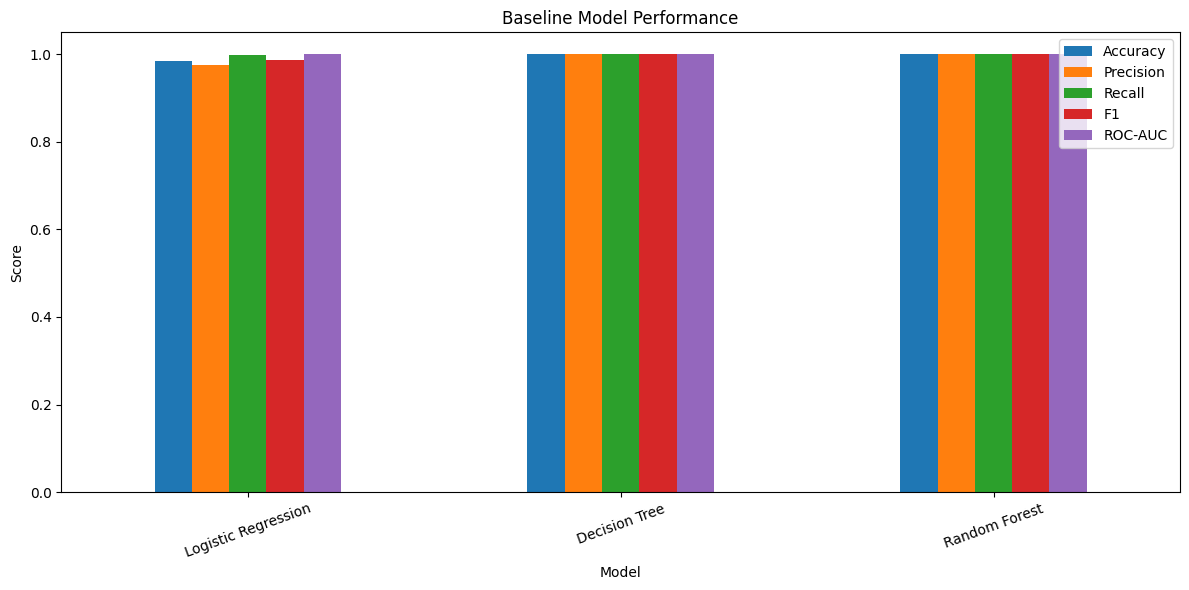

In [22]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

results_plot = results_df.set_index("Model")[metrics]

results_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Baseline Model Performance")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()
plt.show()

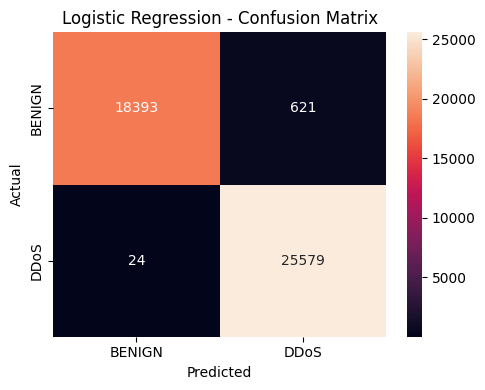

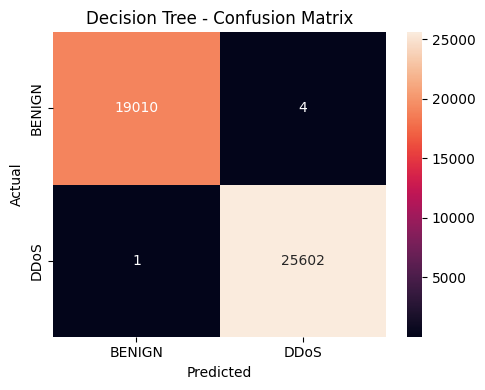

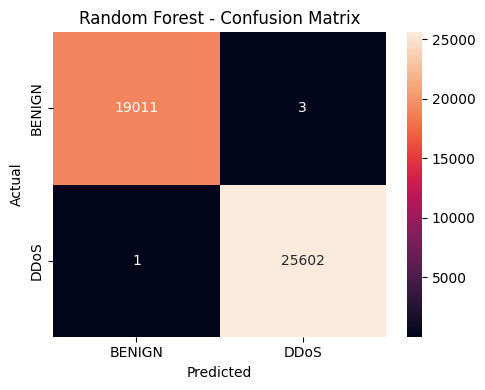

In [23]:
predictions = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf
}

for model_name, predictions_model in predictions.items():

    cm = confusion_matrix(
        y_test,
        predictions_model
    )

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_
    )

    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.tight_layout()
    plt.show()

In [24]:
for model_name, predictions_model in predictions.items():

    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            predictions_model,
            target_names=label_encoder.classes_
        )
    )


Logistic Regression
              precision    recall  f1-score   support

      BENIGN       1.00      0.97      0.98     19014
        DDoS       0.98      1.00      0.99     25603

    accuracy                           0.99     44617
   macro avg       0.99      0.98      0.99     44617
weighted avg       0.99      0.99      0.99     44617


Decision Tree
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     19014
        DDoS       1.00      1.00      1.00     25603

    accuracy                           1.00     44617
   macro avg       1.00      1.00      1.00     44617
weighted avg       1.00      1.00      1.00     44617


Random Forest
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     19014
        DDoS       1.00      1.00      1.00     25603

    accuracy                           1.00     44617
   macro avg       1.00      1.00      1.00     44617
weighted avg       1.00

In [25]:
train_predictions = {
    "Decision Tree": dt_model.predict(X_train),
    "Random Forest": rf_model.predict(X_train)
}

test_predictions = {
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf
}

for model_name in train_predictions:

    train_accuracy = accuracy_score(
        y_train,
        train_predictions[model_name]
    )

    test_accuracy = accuracy_score(
        y_test,
        test_predictions[model_name]
    )

    print("\n", model_name)
    print("Train Accuracy:", round(train_accuracy, 6))
    print("Test Accuracy :", round(test_accuracy, 6))
    print(
        "Gap           :",
        round(train_accuracy - test_accuracy, 6)
    )


 Decision Tree
Train Accuracy: 1.0
Test Accuracy : 0.999888
Gap           : 0.000112

 Random Forest
Train Accuracy: 1.0
Test Accuracy : 0.99991
Gap           : 9e-05


In [26]:
results

[{'Model': 'Logistic Regression',
  'Accuracy': 0.9855436268686824,
  'Precision': 0.9762977099236642,
  'Recall': 0.9990626098504082,
  'F1': 0.9875489836495955,
  'ROC-AUC': 0.9994173120334173,
  'Training Time': 1.0044124126434326,
  'FNR (%)': np.float64(0.09373901495918448)},
 {'Model': 'Decision Tree',
  'Accuracy': 0.9998879350920052,
  'Precision': 0.9998437866125127,
  'Recall': 0.9999609420771003,
  'F1': 0.9999023609131208,
  'ROC-AUC': 0.9998752853858732,
  'Training Time': 0.66939377784729,
  'FNR (%)': np.float64(0.0039057922899660195)},
 {'Model': 'Random Forest',
  'Accuracy': 0.9999103480736042,
  'Precision': 0.9998828353837141,
  'Recall': 0.9999609420771003,
  'F1': 0.9999218872051242,
  'ROC-AUC': 0.9999999435104197,
  'Training Time': 7.92078971862793,
  'FNR (%)': np.float64(0.0039057922899660195)}]

Small train-test gap
        ↓
Less evidence of overfitting

Large train-test gap
        ↓
Possible overfitting

In [27]:
results_df.to_csv(
    "baseline_model_results.csv",
    index=False
)

print("Baseline results saved.")

Baseline results saved.


# Conclusion

Baseline machine-learning models were evaluated using the
selected network traffic features.

All models were evaluated using the same train/test split
and common performance metrics.

The baseline results provide a reference point for evaluating
more advanced models in subsequent experiments.

Model performance was assessed using:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Confusion matrix
- Training time

Train-test performance was also compared to identify possible
overfitting.

These baseline results will be used for comparison with
advanced ensemble, SVM, deep-learning, and other approaches.